# Lab 2
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

## Lab Objective

Investigate why the provided eight-layer `BrokenNet` fails to train on a synthetic binary classification task.

The following steps are followed to reach the final objective:

- Reproduce the failure using the unchanged starter script.
- Inspect gradients and activations to identify the cause.
- Test initialization and normalization changes in separate, controlled stages.
- Compare the loss curves to determine which change contributes most to training.

## Imports and Setup

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# Import custom modules
from scripts.lab02_starter import BrokenNet, make_toy_classification

In [2]:
# Define device (my computer has cpu, but created validator in case it is run with cuda)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch version:', torch.__version__)
print('Device:', device)

PyTorch version: 2.14.0+cpu
Device: cpu


## Stage 0: Baseline Without Changes

The `scripts/lab02_starter.py` file is run first. Its training procedure uses `BrokenNet`, the provided synthetic dataset, plain *SGD* with a *learning rate* of **0.1**, and **50** epochs.

The same procedure is reproduced below to store the loss at every epoch for the final comparison. No changes are made to the starter model.

In [3]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize baseline model, dataset and optimizer
baseline_model = BrokenNet()
x, y = make_toy_classification(seed = 0)
baseline_optimizer = torch.optim.SGD(baseline_model.parameters(), lr = 0.1)

In [4]:
# Create empty losses list
baseline_losses = []

# Training loop
for epoch in range(50):
    baseline_optimizer.zero_grad()

    # Compute logits and loss
    logits = baseline_model(x).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y)

    # Backward pass and optimization step
    loss.backward()
    baseline_optimizer.step()


    baseline_losses.append(loss.item())

    # Print loss every 10 epochs or final epoch
    if epoch % 10 == 0 or epoch == 49:
        print(f'epoch {epoch}   loss = {round(loss.item(), 4)}')

epoch 0   loss = 0.7037
epoch 10   loss = 0.6974
epoch 20   loss = 0.6937
epoch 30   loss = 0.6914
epoch 40   loss = 0.6901
epoch 49   loss = 0.6893


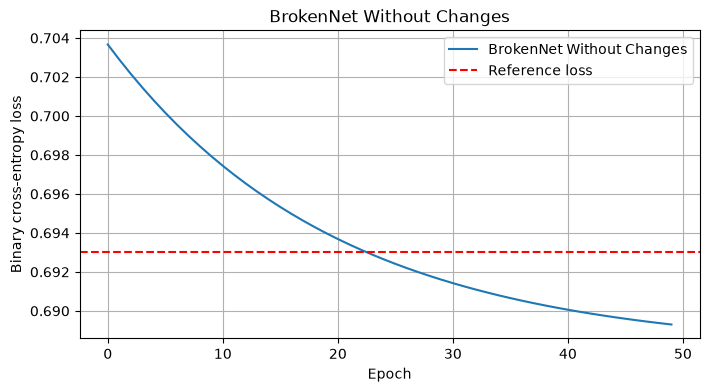

In [5]:
# Plot loss curve for baseline model
plt.figure(figsize=(8, 4))
plt.plot(range(50), baseline_losses, label = 'BrokenNet Without Changes')
plt.axhline(y = 0.693, color = 'red', linestyle = '--', label = 'Reference loss')

# Plot customizations
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('BrokenNet Without Changes')
plt.legend()
plt.grid()

# Show plot
plt.show()

The loss decreases from **0.7037** at epoch 0 to **0.6893** at epoch **49**. Although the loss moves slightly, its final value remains close to approximately **0.693**, the *binary cross-entropy* associated with predictions near **0.5**. The baseline therefore shows little evidence that the model has learned to use the input features.

The loss curve confirms the failure but does not identify its cause. *Gradient* and activation measurements are required before testing a fix.

### Diagnosis: Gradients

Another `BrokenNet` is initialized with the same random seed used in the baseline. Following one forward and backward pass, the mean absolute weight gradient is measured for each hidden layer and the output layer. The output bias gradient is also measured to determine whether the model can update a constant prediction even when its weights receive no learning signal.

In [6]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize diagnostic model
diagnostic_model = BrokenNet()
x, y = make_toy_classification(seed = 0)

# Compute logits and loss
logits = diagnostic_model(x).squeeze(-1)
diagnostic_loss = nn.functional.binary_cross_entropy_with_logits(logits, y)
diagnostic_loss.backward()

# Print initial loss
print(f'Initial loss: {round(diagnostic_loss.item(), 6)}')
# Print mean absolute gradient after one backward pass
print('\nMean absolute gradient after one backward pass:')

# Print mean absolute gradient after one backward pass
for i, layer in enumerate(diagnostic_model.hidden, start = 1):
    weight_gradient = layer.weight.grad.abs().mean().item()
    bias_gradient = layer.bias.grad.abs().mean().item()

    # Print mean absolute gradient after one backward pass for each layer
    print(f'Hidden layer {i}: weight = {round(weight_gradient, 6)} | bias = {round(bias_gradient, 6)}')

# Print mean absolute gradient after one backward pass for output layer
print(f'\nOutput layer: weight = {round(diagnostic_model.out.weight.grad.abs().mean().item(), 6)} | bias = {round(diagnostic_model.out.bias.grad.abs().mean().item(), 6)}')

Initial loss: 0.703666

Mean absolute gradient after one backward pass:
Hidden layer 1: weight = 0.0 | bias = 0.0
Hidden layer 2: weight = 0.0 | bias = 0.0
Hidden layer 3: weight = 0.0 | bias = 0.0
Hidden layer 4: weight = 0.0 | bias = 0.0
Hidden layer 5: weight = 0.0 | bias = 0.0
Hidden layer 6: weight = 0.0 | bias = 0.0
Hidden layer 7: weight = 0.0 | bias = 0.0
Hidden layer 8: weight = 0.0 | bias = 0.0

Output layer: weight = 0.0 | bias = 0.08847


### Diagnosis: Activation

The gradient measurements are complemented with an activation check. For each hidden layer, the percentage of positive pre-activations and non-zero outputs after *ReLU* is measured across the complete synthetic dataset. This identifies the first layer, if any, whose *ReLU* outputs are zero for every example.

In [7]:
# Check if the activations are zero for every example
with torch.no_grad():
    activations = x

    for i, layer in enumerate(diagnostic_model.hidden, start = 1):
        pre_activations = layer(activations)
        activations = torch.relu(pre_activations)

        positive_fraction = (pre_activations > 0).float().mean().item()
        nonzero_fraction = (activations != 0).float().mean().item()

        print(f'Hidden layer {i}: positive before ReLU = {positive_fraction:.2%} | non-zero after ReLU = {nonzero_fraction:.2%}')

Hidden layer 1: positive before ReLU = 6.71% | non-zero after ReLU = 6.71%
Hidden layer 2: positive before ReLU = 0.12% | non-zero after ReLU = 0.12%
Hidden layer 3: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 4: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 5: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 6: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 7: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%
Hidden layer 8: positive before ReLU = 0.00% | non-zero after ReLU = 0.00%


- The baseline loss decreases from **0.7037** to **0.6893** over **50** epochs but remains close to the reference value of approximately **0.693**. After one backward pass, the output weight has no measurable gradient, while the output bias has a mean absolute gradient of **0.08847**.

- The proportion of nonzero activations falls from **6.71%** in hidden layer 1 to **0.12%** in layer 2. Hidden layer 3 is the first to produce zero activations across all 256 examples, and layers 4-8 also produce only zeros. The output therefore depends on its bias rather than on the input features. Bias updates can slightly reduce the loss without learning the classification boundary.

- The hidden layers' initial biases of **-2.0**, together with their weight initialization, make most pre-activations negative. **ReLU** maps these values to zero, blocking the input-dependent signal and its gradients. Initialization and normalization will be tested separately to measure whether they restore training.

## Stage 1: Initialization

The first experiment changes only the hidden layers' initialization. *Kaiming* initialization scales the weights for *ReLU* activations, while setting the hidden biases to zero avoids shifting most initial pre-activations below zero.

The model retains eight hidden layers of *width* **32**, *ReLU* activations, the same synthetic dataset, plain *SGD* with a *learning rate* of**0.1**, and **50** training epochs. No normalization is added at this stage.

In [8]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialization model
initialization_model = BrokenNet()

# Initialize weights and biases
with torch.no_grad():
    for layer in initialization_model.hidden:
        nn.init.kaiming_normal_(layer.weight, mode = 'fan_in', nonlinearity = 'relu')
        nn.init.zeros_(layer.bias)

# Initialize optimizer
initialization_optimizer = torch.optim.SGD(initialization_model.parameters(), lr = 0.1)

# Print model information (hidden layers, optimizer and learning rate)
print("Hidden layers:", len(initialization_model.hidden))
print("Optimizer:", type(initialization_optimizer).__name__)
print("Learning rate:", initialization_optimizer.param_groups[0]["lr"])

Hidden layers: 8
Optimizer: SGD
Learning rate: 0.1


In [9]:
# Compute initial loss and gradient
initialization_optimizer.zero_grad()

# Compute initial logits and loss
initial_logits = initialization_model(x).squeeze(-1)
initial_loss = nn.functional.binary_cross_entropy_with_logits(initial_logits, y)
initial_loss.backward()

# Print initial loss and gradient
print(f'Initial loss: {round(initial_loss.item(), 6)}')
print('\nMean absolute weight gradient before training:')

# Print mean absolute gradient before training for each layer
for i, layer in enumerate(initialization_model.hidden, start=1):
    gradient = layer.weight.grad.abs().mean().item()
    print(f'Hidden layer {i}: {round(gradient, 8)}')

# Print mean absolute gradient before training for output layer
output_gradient = initialization_model.out.weight.grad.abs().mean().item()
print(f'\nOutput layer: {round(output_gradient, 8)}')

Initial loss: 0.762232

Mean absolute weight gradient before training:
Hidden layer 1: 0.00269182
Hidden layer 2: 0.00338514
Hidden layer 3: 0.00283313
Hidden layer 4: 0.00288703
Hidden layer 5: 0.00277307
Hidden layer 6: 0.00239563
Hidden layer 7: 0.00304309
Hidden layer 8: 0.00341433

Output layer: 0.05544587


In [10]:
# Empty list to store losses
initialization_losses = []

# Training loop for initialization model
for epoch in range(50):
    # Zero the gradients
    initialization_optimizer.zero_grad()

    # Compute logits and loss
    logits = initialization_model(x).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y)

    # Backward pass and optimization step
    loss.backward()
    initialization_optimizer.step()

    # Store the loss
    initialization_losses.append(loss.item())

    # Print loss every 10 epochs or final epoch
    if epoch % 10 == 0 or epoch == 49:
        print(f"epoch {round(epoch, 3)}   loss = {round(loss.item(), 4)}")

epoch 0   loss = 0.7622
epoch 10   loss = 0.6561
epoch 20   loss = 0.6234
epoch 30   loss = 0.57
epoch 40   loss = 0.4787
epoch 49   loss = 0.3632


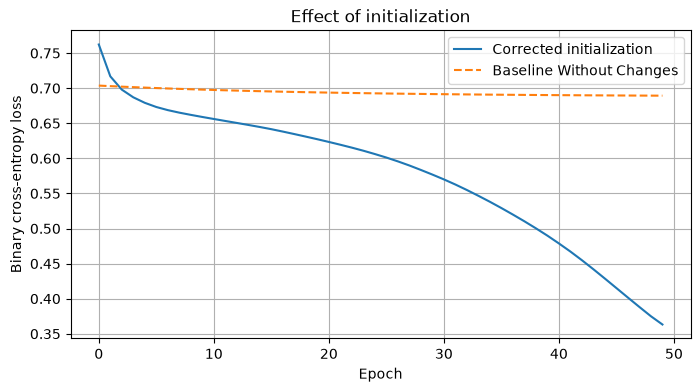

Baseline final loss: 0.689301
Initialization final loss: 0.363229
Change in final loss: -0.326072


In [11]:
# Plot loss curve for initialization model
plt.figure(figsize = (8, 4))
plt.plot(range(50),initialization_losses, label = 'Corrected initialization')
plt.plot(range(50), baseline_losses, linestyle = '--', label = 'Baseline Without Changes')

# Plot customizations
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('Effect of initialization')
plt.legend()
plt.grid()
plt.show()

# Print final loss and change
print(f'Baseline final loss: {round(baseline_losses[-1], 6)}')
print(f'Initialization final loss: {round(initialization_losses[-1], 6)}')
print('Change in final loss: 'f'{round(initialization_losses[-1] - baseline_losses[-1], 6)}')

Corrected initialization restored nonzero weight gradients through the network. Although its initial loss of **0.7622** was higher than the baseline's, the loss decreased consistently to **0.363229** after **50** epochs. The unmodified network ended at **0.689301**, giving a final loss improvement of **0.326072**.

The result supports the diagnosis that the original initialization prevents useful gradient flow. This stage changes the hidden layers' weight scale and bias initialization as one initialization policy. Normalization and the optimizer remain unchanged.

## Stage 2: Normalization

This experiment retains `BrokenNet`'s original weight and bias initialization and adds batch normalization after each hidden linear layer, before *ReLU*. The *depth*, *width*, *activation function*, dataset, *SGD learning rate*, and number of *epochs* remain the same.

Starting from the original initialization isolates the effect of normalization from the *initialization* change tested in *Stage 1*.

In [12]:
# Define NormalizedBrokenNet class with batch normalization after each hidden layer
class NormalizedBrokenNet(BrokenNet):
    
    # Define constructor
    def __init__(self, depth = 8, width = 32, in_features = 20):
        super().__init__(depth = depth, width = width, in_features = in_features)

        self.norms = nn.ModuleList([nn.BatchNorm1d(width) for _ in range(depth)])

    # Define forward pass
    def forward(self, x):
        for layer, norm in zip(self.hidden, self.norms):
            x = torch.relu(norm(layer(x)))
        return self.out(x)

In [13]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize normalization model
normalization_model = NormalizedBrokenNet()
normalization_model.train()

# Initialize optimizer
normalization_optimizer = torch.optim.SGD(normalization_model.parameters(), lr = 0.1)

# Zero the gradients
normalization_optimizer.zero_grad()

# Compute initial logits and loss
normalization_logits = normalization_model(x).squeeze(-1)
normalization_initial_loss = nn.functional.binary_cross_entropy_with_logits(normalization_logits, y)
normalization_initial_loss.backward()

# Print initial loss and gradient
print(f'Initial loss: {round(normalization_initial_loss.item(), 6)}')
print('\nMean absolute weight gradient before training:')

# Print mean absolute gradient before training for each layer
for i, layer in enumerate(normalization_model.hidden, start = 1):
    gradient = layer.weight.grad.abs().mean().item()
    print(f'Hidden layer {i}: {round(gradient, 8)}')

# Print mean absolute gradient before training for output layer
output_gradient = normalization_model.out.weight.grad.abs().mean().item()
print(f'\nOutput layer:   {round(output_gradient, 8)}')

Initial loss: 0.742028

Mean absolute weight gradient before training:
Hidden layer 1: 0.00578017
Hidden layer 2: 0.00377966
Hidden layer 3: 0.00346008
Hidden layer 4: 0.00251536
Hidden layer 5: 0.0021271
Hidden layer 6: 0.00190276
Hidden layer 7: 0.00166589
Hidden layer 8: 0.00147599

Output layer:   0.06443926


In [14]:
# Empty list to store losses
normalization_losses = []

# Training loop for normalization model
for epoch in range(50):
    normalization_optimizer.zero_grad()

    # Compute logits and loss
    logits = normalization_model(x).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y)

    # Backward pass and optimization step
    loss.backward()
    normalization_optimizer.step()

    # Store the loss
    normalization_losses.append(loss.item())

    # Print loss every 10 epochs or final epoch
    if epoch % 10 == 0 or epoch == 49:
        print(f'epoch {round(epoch, 3)}   loss = {round(loss.item(), 4)}')

epoch 0   loss = 0.742
epoch 10   loss = 0.6033
epoch 20   loss = 0.5155
epoch 30   loss = 0.4167
epoch 40   loss = 0.3196
epoch 49   loss = 0.2437


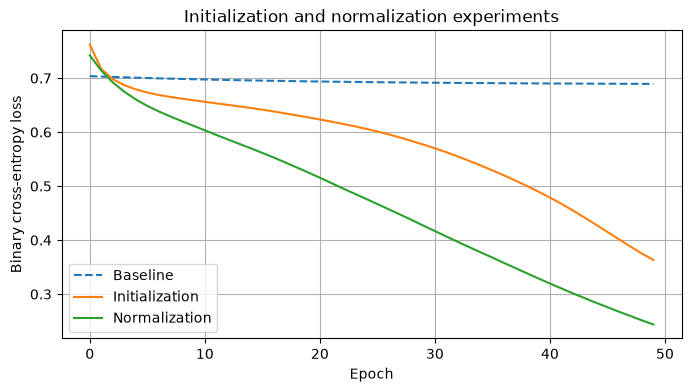

Baseline: 0.689301
Initialization: 0.363229
Normalization: 0.243709


In [15]:
# Plot loss curve for normalization model
plt.figure(figsize = (8, 4))
plt.plot(baseline_losses, label = 'Baseline',linestyle = '--')
plt.plot(initialization_losses, label = 'Initialization')
plt.plot(normalization_losses, label = 'Normalization')

# Plot customizations
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('Initialization and normalization experiments')
plt.legend()
plt.grid()
plt.show()

# Print final loss
print(f'Baseline: {round(baseline_losses[-1], 6)}')
print(f'Initialization: {round(initialization_losses[-1], 6)}')
print(f'Normalization: {round(normalization_losses[-1], 6)}')

Adding batch *normalization* while retaining the starter *initialization* produced non-zero weight gradients and reduced the loss to **0.243709** after **50** epochs. This is an improvement of **0.445592** over the baseline final loss of **0.689301**. Initialization alone ended at **0.363229**, so normalization produced the larger isolated improvement under the same training settings.

Batch *normalization* acts before each *ReLU*. It centers and scales the layer's values across the batch, allowing *activations* to pass through *ReLU* despite the starter's negative biases. This restores gradient flow through the network. The result is measured on the training dataset; performance on unseen examples has not been evaluated.

## Stage 3: Initialization and Normalization

The final training stage combines both normalization and initialization, while the model architecture, *ReLU* activations, dataset, optimizer, learning rate, and **50** training epochs remain fixed.

In [16]:
# Set manual seeds for reproducibility
torch.manual_seed(0)

# Initialize combined model
combined_model = NormalizedBrokenNet()

# Initialize weights and biases
with torch.no_grad():
    for layer in combined_model.hidden:
        nn.init.kaiming_normal_(layer.weight, mode = 'fan_in', nonlinearity = 'relu')
        nn.init.zeros_(layer.bias)

# Set model to training mode
combined_model.train()

# Initialize optimizer
combined_optimizer = torch.optim.SGD(combined_model.parameters(), lr = 0.1)

In [17]:
# Zero the gradients
combined_optimizer.zero_grad()

# Compute initial logits and loss
combined_logits = combined_model(x).squeeze(-1)

# Compute initial loss
combined_initial_loss = nn.functional.binary_cross_entropy_with_logits(combined_logits, y)

# Backward pass and optimization step
combined_initial_loss.backward()

# Print initial loss and gradient
print(f'Initial loss: {round(combined_initial_loss.item(), 6)}')
print('\nMean absolute weight gradient before training:')

# Print mean absolute gradient before training for each layer
for i, layer in enumerate(combined_model.hidden, start = 1):
    gradient = layer.weight.grad.abs().mean().item()
    print(f'Hidden layer {i}: {round(gradient, 8)}')

# Print mean absolute gradient before training for output layer
output_gradient = combined_model.out.weight.grad.abs().mean().item()
print(f'\nOutput layer:   {round(output_gradient, 8)}')

Initial loss: 0.764242

Mean absolute weight gradient before training:
Hidden layer 1: 0.00703312
Hidden layer 2: 0.00542836
Hidden layer 3: 0.00477168
Hidden layer 4: 0.00400006
Hidden layer 5: 0.00317956
Hidden layer 6: 0.00248233
Hidden layer 7: 0.00235376
Hidden layer 8: 0.00161481

Output layer:   0.06138452


In [18]:
# Empty list to store losses
combined_losses = []

# Training loop for combined model (initialization and normalization)
for epoch in range(50):
    # Zero the gradients
    combined_optimizer.zero_grad()

    # Compute logits and loss
    logits = combined_model(x).squeeze(-1)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y)

    # Backward pass and optimization step
    loss.backward()
    combined_optimizer.step()

    # Store the loss
    combined_losses.append(loss.item())

    # Print loss every 10 epochs or final epoch
    if epoch % 10 == 0 or epoch == 49:
        print(f'epoch {round(epoch, 3)}   loss = {round(loss.item(), 4)}')

epoch 0   loss = 0.7642
epoch 10   loss = 0.594
epoch 20   loss = 0.4969
epoch 30   loss = 0.3939
epoch 40   loss = 0.2998
epoch 49   loss = 0.2276


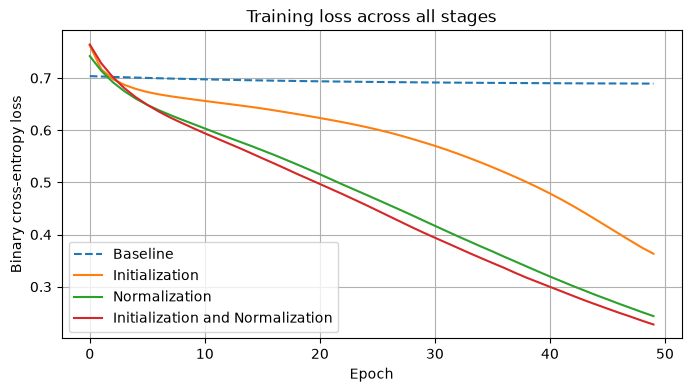

Baseline               0.689301
Initialization         0.363229
Normalization          0.243709
Initialization and Normalization 0.227591


In [19]:
# Plot loss curve for combined model
plt.figure(figsize = (8, 4))
plt.plot(baseline_losses, label='Baseline', linestyle = '--')
plt.plot(initialization_losses, label = 'Initialization')
plt.plot(normalization_losses, label='Normalization')
plt.plot(combined_losses, label = 'Initialization and Normalization')

# Plot customizations
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy loss')
plt.title('Training loss across all stages')
plt.legend()
plt.grid()
plt.show()

# Print final loss
final_losses = {
    'Baseline': baseline_losses[-1],
    'Initialization': initialization_losses[-1],
    'Normalization': normalization_losses[-1],
    'Initialization and Normalization': combined_losses[-1]
    }

# Print final loss
for stage, final_loss in final_losses.items():
    print(f"{stage:<22} {round(final_loss, 6)}")

The baseline network ended at a loss of **0.689301** after 50 epochs. Its hidden activations collapsed to zero by layer 3, preventing signals from reaching the output. The output bias could still update, explaining the small decrease in baseline loss.

Corrected initialization reduced final loss to **0.363229**, while batch normalization alone reduced it to **0.243709**. Normalization therefore made the largest isolated contribution under the fixed training settings: a reduction of **0.445592** relative to the baseline.

Combining both changes produced the lowest loss, **0.227591**. This improved on normalization alone by **0.016118**, showing that corrected initialization added a smaller benefit once normalization was already present.